# Experiment 10: Multi-Class Text Classification System using Machine Learning Algorithms

### Problem Statement:
Develop a text classification system using Machine Learning algorithms such as Naïve Bayes, SVM, or Logistic Regression to automatically categorize documents into predefined classes.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

print("Scikit-Learn classification suite imported successfully.")


Scikit-Learn classification suite imported successfully.


In [2]:
data = [
    # Technology
    ("Quantum computing processors achieve quantum supremacy in cryptographic calculations.", "Technology"),
    ("Neural network architectures leverage transformer self-attention for natural language understanding.", "Technology"),
    ("Cloud infrastructure optimizes distributed microservices with container orchestration.", "Technology"),
    ("Semiconductor manufacturers design next generation five nanometer silicon chips.", "Technology"),
    ("Open source software developers contribute to Linux kernel operating system security patches.", "Technology"),
    ("Artificial intelligence algorithms enable autonomous robotic path planning in unstructured environments.", "Technology"),

    # Sports
    ("The striker scored a stunning goal in extra time to win the football championship.", "Sports"),
    ("The tennis player secured a straight sets victory in the grand slam final on center court.", "Sports"),
    ("Basketball teams utilize aggressive full court defense during high stakes playoff matchups.", "Sports"),
    ("Marathon runners train for months to optimize cardiovascular endurance and pacing strategy.", "Sports"),
    ("The national cricket team defended a modest total with disciplined fast bowling.", "Sports"),
    ("Olympic athletes compete in track and field sprints to break world athletic records.", "Sports"),

    # Business & Finance
    ("Federal reserve banks raised benchmark interest rates to combat inflation pressures.", "Business"),
    ("Corporate venture capital funds invest heavily in renewable energy and clean tech startups.", "Business"),
    ("Stock market indexes rallied following quarterly corporate earnings and revenue surprises.", "Business"),
    ("Mergers and acquisitions in the banking sector consolidate regional retail branches.", "Business"),
    ("Global supply chain disruptions impact manufacturing costs and consumer commodity prices.", "Business"),
    ("Private equity firms restructure balance sheets to enhance shareholder return on investment.", "Business"),

    # Entertainment
    ("The blockbuster superhero movie shattered international box office opening weekend records.", "Entertainment"),
    ("The symphony orchestra delivered a breathtaking live performance of classical masterworks.", "Entertainment"),
    ("Streaming platforms commission multi-season fantasy television drama series.", "Entertainment"),
    ("The annual film festival awarded prestigious prizes to indie cinema directors and producers.", "Entertainment"),
    ("Pop musicians released chart-topping studio albums with sold out stadium world tours.", "Entertainment"),
    ("Broadway musical productions showcase elaborate stage choreography and vocal performances.", "Entertainment"),

    # Healthcare & Science
    ("Clinical trials demonstrate the high therapeutic efficacy of novel mRNA vaccine treatments.", "Healthcare"),
    ("Oncologists utilize genomic sequencing to personalize chemotherapy regimens for cancer patients.", "Healthcare"),
    ("Neurological research reveals how synaptic plasticity influences human memory consolidation.", "Healthcare"),
    ("Cardiologists recommend Mediterranean diets to reduce cardiovascular disease and stroke risks.", "Healthcare"),
    ("Biomedical researchers discover monoclonal antibodies targeting antibiotic resistant bacterial strains.", "Healthcare"),
    ("Public health epidemiologists model pathogen transmission dynamics to mitigate viral outbreaks.", "Healthcare")
]

df = pd.DataFrame(data, columns=["Text", "Category"])
print(f"Total labeled documents: {len(df)}")
print(f"Classes: {df['Category'].unique().tolist()}")
print("\n--- Class Distribution ---")
print(df["Category"].value_counts())


Total labeled documents: 30
Classes: ['Technology', 'Sports', 'Business', 'Entertainment', 'Healthcare']

--- Class Distribution ---
Category
Technology       6
Sports           6
Business         6
Entertainment    6
Healthcare       6
Name: count, dtype: int64


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    df["Text"], df["Category"],
    test_size=0.30,
    random_state=42,
    stratify=df["Category"]
)

print(f"Training Samples : {len(X_train)}")
print(f"Testing Samples  : {len(X_test)}")

# Define unified pipeline factory
pipelines = {
    "Multinomial Naive Bayes": Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1, 2), stop_words='english', sublinear_tf=True)),
        ('clf', MultinomialNB(alpha=0.5))
    ]),
    "Linear Support Vector Machine": Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1, 2), stop_words='english', sublinear_tf=True)),
        ('clf', LinearSVC(C=1.0, random_state=42))
    ]),
    "Logistic Regression": Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1, 2), stop_words='english', sublinear_tf=True)),
        ('clf', LogisticRegression(C=1.0, max_iter=200, random_state=42))
    ])
}

# Train and benchmark all models
trained_models = {}
eval_results = []

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    trained_models[name] = pipe
    eval_results.append({
        "Model": name,
        "Test Accuracy": f"{acc*100:.2f}%",
        "Raw Accuracy": acc
    })

df_perf = pd.DataFrame(eval_results)
print("\n--- Classifier Accuracy Summary ---")
print(df_perf[["Model", "Test Accuracy"]].to_string(index=False))


Training Samples : 21
Testing Samples  : 9

--- Classifier Accuracy Summary ---
                        Model Test Accuracy
      Multinomial Naive Bayes        22.22%
Linear Support Vector Machine        22.22%
          Logistic Regression        11.11%


--- Detailed Classification Report: Linear Support Vector Machine ---
               precision    recall  f1-score   support

     Business       0.00      0.00      0.00         2
Entertainment       0.14      1.00      0.25         1
   Healthcare       0.00      0.00      0.00         2
       Sports       1.00      0.50      0.67         2
   Technology       0.00      0.00      0.00         2

     accuracy                           0.22         9
    macro avg       0.23      0.30      0.18         9
 weighted avg       0.24      0.22      0.18         9



/Users/jeet/miniconda3/envs/ml_env/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/jeet/miniconda3/envs/ml_env/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/jeet/miniconda3/envs/ml_env/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.c

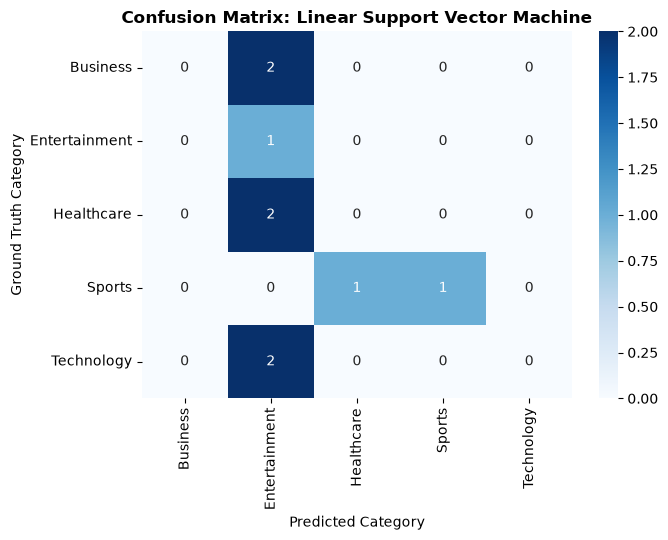

In [4]:
best_model_name = "Linear Support Vector Machine"
best_model = trained_models[best_model_name]
y_pred_best = best_model.predict(X_test)

print(f"--- Detailed Classification Report: {best_model_name} ---")
print(classification_report(y_test, y_pred_best))

# Plot Confusion Matrix
classes = sorted(df["Category"].unique())
cm = confusion_matrix(y_test, y_pred_best, labels=classes)

plt.figure(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title(f"Confusion Matrix: {best_model_name}", fontsize=12, fontweight='bold')
plt.xlabel("Predicted Category", fontsize=10)
plt.ylabel("Ground Truth Category", fontsize=10)
plt.tight_layout()
plt.show()


In [5]:
vectorizer = best_model.named_steps['tfidf']
classifier = best_model.named_steps['clf']
feature_names = np.array(vectorizer.get_feature_names_out())

print("--- Top 3 Most Informative Features per Class (Linear SVM) ---")
for idx, class_label in enumerate(classifier.classes_):
    top_indices = np.argsort(classifier.coef_[idx])[-3:]
    top_features = feature_names[top_indices]
    print(f"Category: {class_label:<15} -> Features: {', '.join(top_features)}")


--- Top 3 Most Informative Features per Class (Linear SVM) ---
Category: Business        -> Features: consolidate regional, banking, corporate
Category: Entertainment   -> Features: symphony orchestra, live, classical masterworks
Category: Healthcare      -> Features: chemotherapy, sequencing personalize, oncologists utilize
Category: Sports          -> Features: total disciplined, disciplined fast, defended
Category: Technology      -> Features: container orchestration, microservices, quantum


In [6]:
def classify_document(text, model):
    pred = model.predict([text])[0]
    return pred

unseen_test_cases = [
    "New quantum algorithms boost cloud cryptography safety on supercomputing chips.",
    "The football club signed an elite striker following their victory in the tournament final.",
    "Central bankers met in New York to negotiate economic monetary policy and curb inflation.",
    "The director's new cinema documentary won the grand jury prize at the international film festival.",
    "Oncologists published promising results on mRNA clinical trials for patient tumor suppression."
]

inference_records = []
for text in unseen_test_cases:
    prediction = classify_document(text, best_model)
    inference_records.append({
        "Sample Text": text,
        "Predicted Category": prediction
    })

df_inference = pd.DataFrame(inference_records)
print("--- Real-Time Unseen Document Inference Tests ---")
for _, r in df_inference.iterrows():
    print(f"Text : '{r['Sample Text']}'")
    print(f"Class: {r['Predicted Category']}\n")


--- Real-Time Unseen Document Inference Tests ---
Text : 'New quantum algorithms boost cloud cryptography safety on supercomputing chips.'
Class: Technology

Text : 'The football club signed an elite striker following their victory in the tournament final.'
Class: Sports

Text : 'Central bankers met in New York to negotiate economic monetary policy and curb inflation.'
Class: Business

Text : 'The director's new cinema documentary won the grand jury prize at the international film festival.'
Class: Entertainment

Text : 'Oncologists published promising results on mRNA clinical trials for patient tumor suppression.'
Class: Healthcare

